##Langkah 1.1 Lembar hitung manual


In [28]:
# ==========================================
# LEMBAR HITUNG 1.1 - PERHITUNGAN MANUAL
# ==========================================

import numpy as np

# Matriks citra kanal R dari petunjuk praktikum
A = np.array([
    [52, 55, 180],
    [50, 58, 185],
    [54, 60, 190]
], dtype=np.float32)

# Kernel Sobel
sobel_kx = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1]
], dtype=np.float32)

sobel_ky = sobel_kx.T

# Kernel Prewitt
prewitt_kx = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1]
], dtype=np.float32)

prewitt_ky = prewitt_kx.T

# Kernel Laplacian
laplacian = np.array([
    [0, 1, 0],
    [1, -4, 1],
    [0, 1, 0]
], dtype=np.float32)


# Fungsi perhitungan gradien
def hitung_gradien(A, kx, ky):
    gx = np.sum(A * kx)
    gy = np.sum(A * ky)
    magnitudo = np.sqrt(gx**2 + gy**2)
    pendekatan = abs(gx) + abs(gy)
    arah = np.degrees(np.arctan2(gy, gx))
    arah_tepi = (arah + 90) % 180

    return gx, gy, magnitudo, pendekatan, arah, arah_tepi


# Menampilkan matriks
print("MATRIKS CITRA KANAL R:")
print(A)

# ==========================================
# A. PERHITUNGAN SOBEL
# ==========================================

gx_s, gy_s, mag_s, pendek_s, arah_s, tepi_s = hitung_gradien(
    A, sobel_kx, sobel_ky
)

print("\nA. PERHITUNGAN SOBEL")
print("Gx =", gx_s)
print("Gy =", gy_s)
print("Magnitudo = sqrt(Gx^2 + Gy^2)")
print(f"Magnitudo = {mag_s:.2f}")
print(f"Pendekatan |Gx| + |Gy| = {pendek_s:.2f}")
print(f"Arah gradien = {arah_s:.2f} derajat")
print(f"Arah tepi = {tepi_s:.2f} derajat")


# ==========================================
# B. PERHITUNGAN PREWITT
# ==========================================

gx_p, gy_p, mag_p, pendek_p, arah_p, tepi_p = hitung_gradien(
    A, prewitt_kx, prewitt_ky
)

print("\nB. PERHITUNGAN PREWITT")
print("Gx =", gx_p)
print("Gy =", gy_p)
print("Magnitudo = sqrt(Gx^2 + Gy^2)")
print(f"Magnitudo = {mag_p:.2f}")
print(f"Pendekatan |Gx| + |Gy| = {pendek_p:.2f}")
print(f"Arah gradien = {arah_p:.2f} derajat")
print(f"Arah tepi = {tepi_p:.2f} derajat")


# ==========================================
# C. PERHITUNGAN LAPLACIAN
# ==========================================

respons_laplacian = np.sum(A * laplacian)

print("\nC. PERHITUNGAN LAPLACIAN")
print("Respons Laplacian =", respons_laplacian)

if respons_laplacian > 0:
    print("Tanda positif: nilai pusat lebih rendah daripada kombinasi tetangganya.")
elif respons_laplacian < 0:
    print("Tanda negatif: nilai pusat lebih tinggi daripada kombinasi tetangganya.")
else:
    print("Respons Laplacian bernilai nol.")


# ==========================================
# D. ARAH TEPI
# ==========================================

print("\nD. ARAH TEPI")
print(f"Arah gradien Sobel = {arah_s:.2f} derajat")
print(f"Arah tepi Sobel = {tepi_s:.2f} derajat")
print("Arah tepi tegak lurus terhadap arah gradien.")

MATRIKS CITRA KANAL R:
[[ 52.  55. 180.]
 [ 50.  58. 185.]
 [ 54.  60. 190.]]

A. PERHITUNGAN SOBEL
Gx = 534.0
Gy = 22.0
Magnitudo = sqrt(Gx^2 + Gy^2)
Magnitudo = 534.45
Pendekatan |Gx| + |Gy| = 556.00
Arah gradien = 2.36 derajat
Arah tepi = 92.36 derajat

B. PERHITUNGAN PREWITT
Gx = 399.0
Gy = 17.0
Magnitudo = sqrt(Gx^2 + Gy^2)
Magnitudo = 399.36
Pendekatan |Gx| + |Gy| = 416.00
Arah gradien = 2.44 derajat
Arah tepi = 92.44 derajat

C. PERHITUNGAN LAPLACIAN
Respons Laplacian = 118.0
Tanda positif: nilai pusat lebih rendah daripada kombinasi tetangganya.

D. ARAH TEPI
Arah gradien Sobel = 2.36 derajat
Arah tepi Sobel = 92.36 derajat
Arah tepi tegak lurus terhadap arah gradien.


# Kode 1.1 Persiapan: modul, data, praproses, dan tepi acuan

In [29]:
# Menghubungkan Google Drive
from google.colab import drive
drive.mount('/content/drive')

# Import library
import os
import sys
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib

# Menentukan folder proyek
ROOT = "/content/drive/MyDrive/simuteh-2330511004"

# Masuk ke folder notebook
os.chdir(os.path.join(ROOT, "notebook"))

# Menghubungkan folder src
if "../src" not in sys.path:
    sys.path.append("../src")

# Import modul dari P1-P4
from utils_cv import baca, tampil
from praproses import praproses
from utils_tepi import (
    tepi_acuan,
    skor_tepi,
    iou,
    mask_daun_awal,
    bercak_awal
)

# Pengaturan tampilan
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
plt.rcParams["figure.dpi"] = 100

# Membaca parameter praproses P1-P4
PARAM = json.load(open("../hasil/param_praproses.json"))

# Membaca dataset
label = pd.read_csv("../data/sintetis/label.csv")

# Fungsi memuat citra dan mask
def muat(nama):
    img = baca(f"../data/sintetis/citra/{nama}")
    md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
    mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)
    return img, md, mb

# Membuat folder hasil
os.makedirs("../hasil", exist_ok=True)

print("Jumlah citra:", len(label))
print("Parameter praproses:")
print(PARAM)

print("\nJumlah data berdasarkan kelas:")
display(label["kelas"].value_counts())

print("\nJumlah data berdasarkan pencahayaan:")
display(label["kondisi_cahaya"].value_counts())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Jumlah citra: 60
Parameter praproses:
{'lebar': 640, 'gamma': 'auto', 'clahe_clip': 1.0, 'clahe_tile': 4, 'clahe_otomatis': True, 'batas_tidak_rata': 0.65, 'penapis': 'median', 'kernel': 3, 'sigma': 1.0, 'tajam_k': 0.0}

Jumlah data berdasarkan kelas:


,count
kelas,
sehat,20
ringan,20
berat,20



Jumlah data berdasarkan pencahayaan:


,count
kondisi_cahaya,
normal,12
gelap,12
terang,12
kontras_rendah,12
bayangan,12


Ukuran citra mentah: (480, 640, 3)
Ukuran citra praproses: (480, 640, 3)
Modul P5 berhasil dimuat.


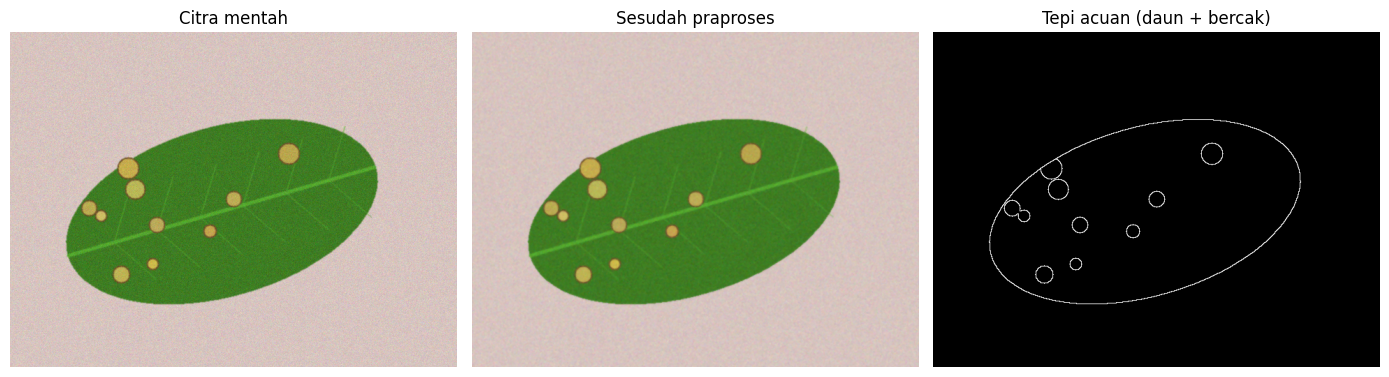

In [30]:
# Memuat ulang modul
import utils_tepi
importlib.reload(utils_tepi)

# Mengambil satu citra contoh
img, md, mb = muat("teh_041.png")

# Menerapkan praproses P1-P4
pra = praproses(img, PARAM)

# Membuat tepi acuan
acuan = cv2.bitwise_or(
    utils_tepi.tepi_acuan(md),
    utils_tepi.tepi_acuan(mb)
)

# Menampilkan hasil
tampil(
    [img, pra, acuan],
    [
        "Citra mentah",
        "Sesudah praproses",
        "Tepi acuan (daun + bercak)"
    ]
)

print("Ukuran citra mentah:", img.shape)
print("Ukuran citra praproses:", pra.shape)
print("Modul P5 berhasil dimuat.")

## Kode 1.2 Gradien Sobel manual: Gx, Gy, magnitudo, dan arah


selisih maks gx manual vs cv2.Sobel: 0.0
magnitudo maks: 550.8


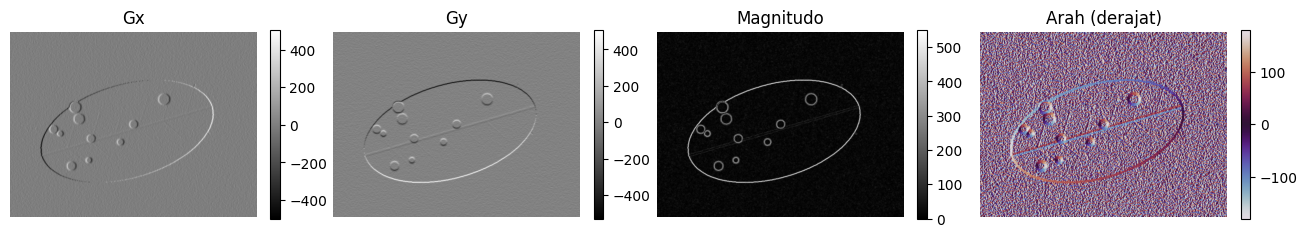

In [31]:
g = pra[:, :, 2].astype(np.float32) # kanal R hasil praproses
kx = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32)
ky = kx.T
gx = cv2.filter2D(g, cv2.CV_32F, kx) # turunan arah x (tepi vertikal)
gy = cv2.filter2D(g, cv2.CV_32F, ky) # turunan arah y (tepi horizontal)
mag = np.sqrt(gx ** 2 + gy ** 2)
arah = np.degrees(np.arctan2(gy, gx))
# bandingkan dengan fungsi pustaka
gx_cv = cv2.Sobel(g, cv2.CV_32F, 1, 0, ksize=3)
print("selisih maks gx manual vs cv2.Sobel:", np.abs(gx - gx_cv).max())
print("magnitudo maks:", mag.max().round(1))
plt.figure(figsize=(16, 3.6))
for i, (c, jd) in enumerate([(gx, "Gx"), (gy, "Gy"), (mag, "Magnitudo"), (arah,
"Arah (derajat)")]):
 plt.subplot(1, 4, i + 1); plt.imshow(c, cmap="twilight" if i == 3 else
"gray")
 plt.title(jd); plt.axis("off"); plt.colorbar(fraction=0.035)

## Langkah 1.3 Empat operator pada satu citra.
### Kode 1.3 Fungsi Sobel, Prewitt, LoG, dan Canny serta perbandingannya

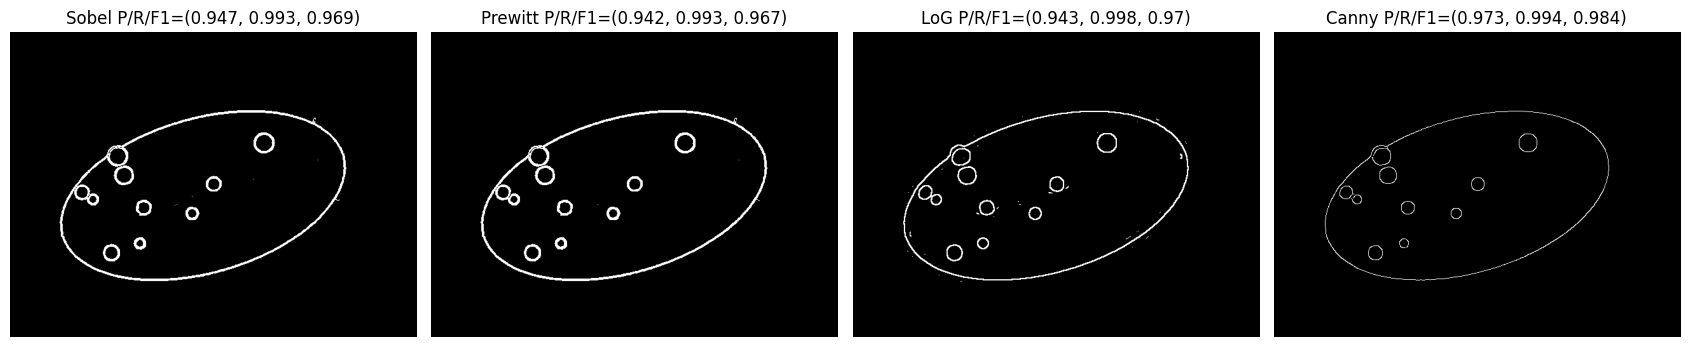

In [32]:
def tepi_sobel(g, T=100):
  g = g.astype(np.float32)
  m = np.hypot(cv2.Sobel(g, cv2.CV_32F, 1, 0), cv2.Sobel(g, cv2.CV_32F, 0, 1))
  return ((m > T) * 255).astype(np.uint8)
def tepi_prewitt(g, T=75):
  kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], np.float32)
  g = g.astype(np.float32)
  m = np.hypot(cv2.filter2D(g, -1, kx), cv2.filter2D(g, -1, kx.T))
  return ((m > T) * 255).astype(np.uint8)
def tepi_log(g, sigma=3.0, frac=0.2):
 """Laplacian of Gaussian: tepi = perlintasan nol yang cukup kuat."""
 L = cv2.Laplacian(cv2.GaussianBlur(g.astype(np.float32), (0, 0), sigma),
cv2.CV_32F)
 mn, mx = cv2.erode(L, np.ones((3, 3))), cv2.dilate(L, np.ones((3, 3)))
 return (((mn < 0) & (mx > 0) & (mx - mn > frac * np.abs(L).max())) *
255).astype(np.uint8)
def tepi_canny(g, lo=30, hi=90, sigma=2.0):
    if sigma > 0:
        g = cv2.GaussianBlur(g, (0, 0), sigma)

    return cv2.Canny(g, lo, hi)

metode = {"Sobel": tepi_sobel, "Prewitt": tepi_prewitt, "LoG": tepi_log,
"Canny": tepi_canny}
g = pra[:, :, 2]
hasil = {nm: f(g) for nm, f in metode.items()}
tampil(list(hasil.values()), [f"{nm} P/R/F1={skor_tepi(e, acuan)}" for nm, e
in hasil.items()],
 ukuran=(17, 3.6))

## Langkah 1.4 Perbandingan menyeluruh
### Kode 1.4 Tabel presisi, recall, dan F1 tepi

In [27]:
baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
  img, md, mb = muat(d.nama_file)
  ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
  for sumber, im in [("mentah", img), ("praproses", praproses(img, PARAM))]:
    for kanal, g in [("Gray", cv2.cvtColor(im, cv2.COLOR_BGR2GRAY)), ("R",
                                                                      im[:, :, 2])]:
                                                                      for nm, f in metode.items():
                                                                        p, r, f1 = skor_tepi(f(g), ac)
                                                                        baris.append([d.kondisi_cahaya, sumber, kanal, nm, p, r, f1])
                                                                        tabel_tepi = pd.DataFrame(baris, columns=["kondisi", "sumber", "kanal",
"metode", "P", "R", "F1"])
ringkas = tabel_tepi.groupby(["sumber", "kanal", "metode"])[["P", "R",
"F1"]].mean().round(3)
print(ringkas)
tabel_tepi.to_csv("../hasil/p5_tabel_tepi.csv", index=False)

                             P      R     F1
sumber    kanal metode                      
mentah    Gray  Canny    0.740  0.750  0.743
                LoG      0.599  0.997  0.740
                Prewitt  0.786  0.963  0.858
                Sobel    0.750  0.970  0.835
          R     Canny    0.984  0.977  0.979
                LoG      0.873  0.998  0.921
                Prewitt  0.598  0.996  0.694
                Sobel    0.545  0.996  0.643
praproses Gray  Canny    0.751  0.755  0.753
                LoG      0.602  0.997  0.741
                Prewitt  0.878  0.831  0.788
                Sobel    0.872  0.845  0.803
          R     Canny    0.984  0.968  0.974
                LoG      0.878  0.998  0.924
                Prewitt  0.875  0.984  0.918
                Sobel    0.858  0.985  0.906


## Grafik batang yang membandingkan nilai F1 dari empat operator deteksi tepi pada setiap kondisi cahaya.

In [33]:
# Mengambil data kanal R sesudah praproses
data_f1 = tabel_tepi[
    (tabel_tepi["sumber"] == "praproses") &
    (tabel_tepi["kanal"] == "R")
]

# Menghitung rata-rata F1 berdasarkan kondisi cahaya dan operator
ringkas_f1 = data_f1.pivot_table(
    index="kondisi",
    columns="metode",
    values="F1",
    aggfunc="mean"
)

# Menampilkan tabel F1
display(ringkas_f1.round(3))

metode,Canny,LoG,Prewitt,Sobel
kondisi,,,,
bayangan,0.979,0.963,0.897,0.879
gelap,0.987,0.936,0.870,0.853
kontras_rendah,0.923,0.793,0.961,0.964
normal,0.991,0.975,0.970,0.972
terang,0.992,0.955,0.891,0.863


<Figure size 1200x600 with 0 Axes>

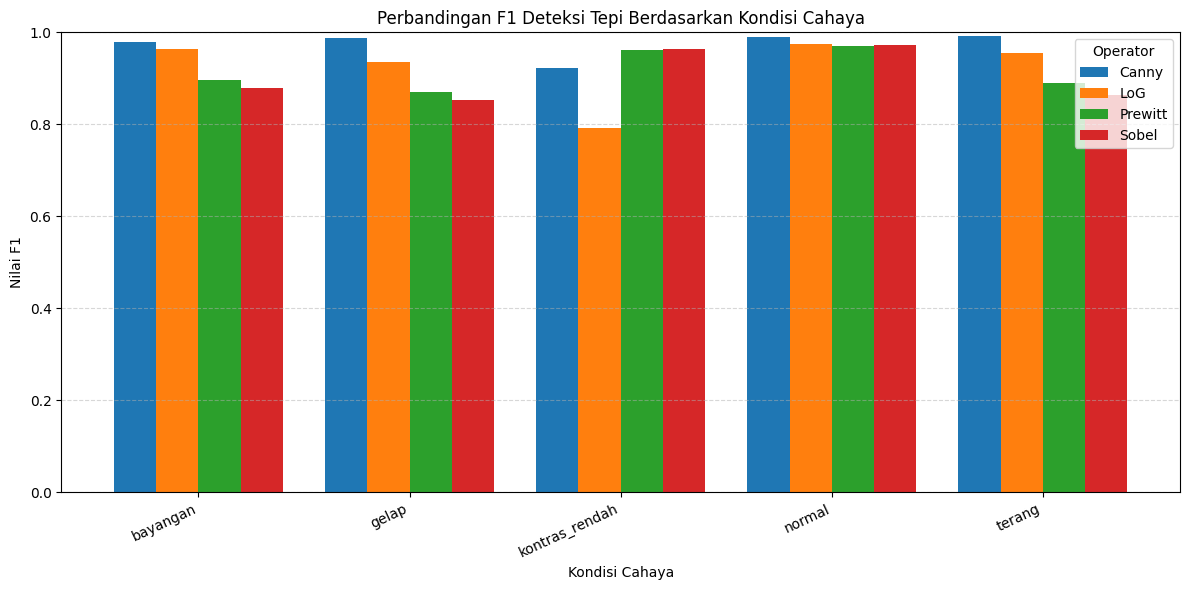

In [34]:
plt.figure(figsize=(12, 6))

ringkas_f1.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Perbandingan F1 Deteksi Tepi Berdasarkan Kondisi Cahaya")
plt.xlabel("Kondisi Cahaya")
plt.ylabel("Nilai F1")
plt.ylim(0, 1)
plt.xticks(rotation=25, ha="right")
plt.legend(title="Operator")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()

# Simpan grafik sesuai petunjuk praktikum
plt.savefig("../hasil/p5_f1_kondisi.png", dpi=300, bbox_inches="tight")

plt.show()

**P1.1**
* Alasan |Gx| >> |Gy|: Dari Lembar Hitung 1.1, matriks A menunjukkan perubahan intensitas yang sangat drastis secara horizontal (dari kolom kiri ke kanan, misal 52 menjadi 180) tetapi sangat kecil secara vertikal (dari baris atas ke bawah, misal 52 ke 50 ke 54). Kernel Sobel Kx mendeteksi perubahan horizontal (tepi vertikal), sehingga menghasilkan Gx = 534.0. Kernel Ky mendeteksi perubahan vertikal (tepi horizontal), menghasilkan Gy = 22.0. Jadi, |Gx| jauh lebih besar karena pada area tersebut terdapat tepi yang hampir tegak lurus (vertikal).

 * Hubungan arah gradien dengan arah tepi: Gradien menunjuk ke arah perubahan intensitas maksimum (tegak lurus terhadap tepi). Jika gradien dominan horizontal (Gx besar, Gy kecil), maka tepi objek berorientasi vertikal. Sebaliknya, jika gradien dominan vertikal, tepi berorientasi horizontal.

* Hubungan pada panel arah Kode 1.2: Pada panel "Arah (derajat)", warna menunjukkan sudut gradien. Area dengan tepi vertikal (seperti batas kiri/kanan daun) akan memiliki gradien horizontal (sudut mendekati 0° atau 180°, ditandai warna merah/kuning). Area dengan tepi horizontal (seperti batas atas/bawah daun atau tulang daun) akan memiliki gradien vertikal (sudut mendekati 90° atau -90°, ditandai warna biru/hijau)

**P1.2**

* Alasan: Kernel Sobel memberikan bobot lebih besar pada piksel pusat (bobot 2) dibandingkan Prewitt yang memberikan bobot seragam (bobot 1). Hal ini membuat Sobel lebih sensitif terhadap perubahan intensitas di sekitar pusat, sehingga magnitudonya lebih besar (Sobel |G| = 534.45, Prewitt |G| = 399.36).

* Akibat jika T sama: Jika ambang T diset sama (misal T=100) untuk keduanya, Sobel akan mendeteksi lebih banyak piksel tepi (termasuk lebih banyak noise/tepi palsu) karena magnitudonya lebih tinggi. Prewitt mungkin akan kehilangan beberapa tepi yang lemah. Untuk hasil yang setara, ambang Prewitt harus diset lebih rendah daripada ambang Sobel.

**P1.3**

1. Berdasarkan data pada tabel (gambar hasil):

* Sobel & Prewitt: Secara umum, kanal Gray memberikan F1 lebih tinggi pada citra mentah (Sobel 0.835 vs 0.643; Prewitt 0.858 vs 0.694). Namun, setelah praproses, kanal R melonjak sangat tinggi (Sobel 0.906; Prewitt 0.918) melampaui Gray.

* Canny & LoG: Kanal R secara konsisten memberikan F1 tertinggi baik sebelum maupun sesudah praproses (Canny R: 0.979; LoG R: 0.921).

2. Kaitan dengan Kontras Bercak (KB): Kanal R (Red) sangat efektif untuk memisahkan bercak cokelat dari daun hijau karena kontras warna yang tinggi. Praproses (seperti CLAHE dan koreksi gamma) berhasil menonjolkan kontras ini pada kanal R, sehingga gradien tepi bercak menjadi lebih tajam dan mudah dideteksi oleh operator seperti Canny dan LoG. Pada kanal Gray, bercak dan daun bisa memiliki intensitas yang mirip (kontras rendah), sehingga tepi sulit dideteksi.

**P1.4**

* Berdasarkan tabel, praproses menurunkan F1 untuk kombinasi Prewitt dan Sobel pada kanal Gray (Prewitt: 0.858 -> 0.788; Sobel: 0.835 -> 0.803), serta sedikit menurunkan F1 Canny pada kanal R (0.979 -> 0.974).

* Penyebab: Praproses menggunakan penapis median (median filter) dan CLAHE. Penapis median bertujuan meredam noise, tetapi efek sampingnya adalah menghaluskan (blurring) tepi objek. Operator gradien seperti Sobel dan Prewitt sangat bergantung pada ketajaman perubahan intensitas; jika tepi dihaluskan, magnitudo gradien menurun, sehingga piksel tepi yang sebelumnya lolos ambang bisa hilang (menurunkan Recall) atau bergeser (menurunkan Presisi). Untuk Canny, praproses membantu menormalkan pencahayaan, tetapi jika penapis terlalu kuat, bercak kecil bisa ikut terhapus

**P1.5**

* Cara kerja Zero Crossing: LoG (Laplacian of Gaussian) adalah turunan kedua dari citra yang telah dihaluskan dengan Gaussian. Tepi pada LoG dideteksi ketika nilai respons Laplacian berubah tanda dari positif ke negatif (atau sebaliknya) melewati angka nol. Titik di mana nilai tersebut tepat nol (atau terjadi perubahan tanda antar piksel bertetangga) disebut zero-crossing.

* Mengapa banyak tepi palsu: Turunan kedua sangat sensitif terhadap noise frekuensi tinggi. Jika ambang (threshold) tidak memadai—seperti parameter frac pada Kode 1.3 yang berfungsi menyaring perlintasan lemah—maka fluktuasi kecil pada piksel (misalnya tekstur permukaan daun atau noise sensor) akan terdeteksi sebagai perubahan tanda (zero-crossing). Akibatnya, LoG akan menandai hampir semua variasi kecil sebagai tepi, menghasilkan Recall yang sangat tinggi (hampir 1.0) tetapi Presisi yang rendah karena banyak tepi palsu (false positives).



## Langkah 2.1 Lembar hitung manual

In [43]:

import numpy as np

# ==========================================
# A. NON-MAXIMUM SUPPRESSION (NMS)
# ==========================================

M1 = np.array([
    [30, 40, 35],
    [90, 100, 95],
    [20, 30, 25]
])

M2 = np.array([
    [50, 60, 55],
    [85, 80, 70],
    [40, 45, 50]
])

def hitung_nms(M, arah):
    tengah = M[1, 1]

    if arah == 0:
        # Tetangga kiri dan kanan
        a = M[1, 0]
        b = M[1, 2]

    elif arah == 90:
        # Tetangga atas dan bawah
        a = M[0, 1]
        b = M[2, 1]

    else:
        raise ValueError("Arah harus 0 atau 90 derajat")

    if tengah >= a and tengah >= b:
        hasil = tengah
        status = "Dipertahankan"
    else:
        hasil = 0
        status = "Ditekan menjadi 0"

    print(f"Arah gradien       : {arah} derajat")
    print(f"Tetangga pertama   : {a}")
    print(f"Piksel tengah      : {tengah}")
    print(f"Tetangga kedua     : {b}")
    print(f"Hasil NMS          : {hasil}")
    print(f"Keputusan          : {status}")
    print("-" * 40)

    return hasil


print("HASIL NMS MATRIKS M1")
print("Matriks:")
print(M1)

hasil_M1_0 = hitung_nms(M1, 0)
hasil_M1_90 = hitung_nms(M1, 90)


print("\nHASIL NMS MATRIKS M2")
print("Matriks:")
print(M2)

hasil_M2_0 = hitung_nms(M2, 0)
hasil_M2_90 = hitung_nms(M2, 90)


# ==========================================
# B. HYSTERESIS THRESHOLDING
# ==========================================

magnitudo = np.array([20, 60, 120, 80, 40, 90, 30])

ambang_bawah = 50
ambang_atas = 100

# Klasifikasi awal:
# 0 = bukan tepi
# 1 = tepi lemah
# 2 = tepi kuat

kategori = np.zeros(len(magnitudo), dtype=int)

kategori[magnitudo >= ambang_bawah] = 1
kategori[magnitudo >= ambang_atas] = 2

# Hysteresis:
# Tepi kuat dipertahankan.
# Tepi lemah dipertahankan jika bersebelahan
# dengan tepi kuat.

hasil_akhir = np.zeros(len(magnitudo), dtype=int)

for i in range(len(magnitudo)):
    if kategori[i] == 2:
        hasil_akhir[i] = 1

    elif kategori[i] == 1:
        tetangga_kuat = (
            (i > 0 and kategori[i - 1] == 2) or
            (i < len(magnitudo) - 1 and kategori[i + 1] == 2)
        )

        if tetangga_kuat:
            hasil_akhir[i] = 1


print("\nHASIL HYSTERESIS THRESHOLDING")
print("Magnitudo awal :", magnitudo)
print("Kategori awal  :", kategori)
print("Hasil akhir    :", hasil_akhir)

print("\nKeterangan:")
print("0 = Bukan tepi")
print("1 = Tepi lemah (kategori awal)")
print("2 = Tepi kuat (kategori awal)")
print("Hasil akhir 1 = Tepi dipertahankan")
print("Hasil akhir 0 = Tepi dibuang")


HASIL NMS MATRIKS M1
Matriks:
[[ 30  40  35]
 [ 90 100  95]
 [ 20  30  25]]
Arah gradien       : 0 derajat
Tetangga pertama   : 90
Piksel tengah      : 100
Tetangga kedua     : 95
Hasil NMS          : 100
Keputusan          : Dipertahankan
----------------------------------------
Arah gradien       : 90 derajat
Tetangga pertama   : 40
Piksel tengah      : 100
Tetangga kedua     : 30
Hasil NMS          : 100
Keputusan          : Dipertahankan
----------------------------------------

HASIL NMS MATRIKS M2
Matriks:
[[50 60 55]
 [85 80 70]
 [40 45 50]]
Arah gradien       : 0 derajat
Tetangga pertama   : 85
Piksel tengah      : 80
Tetangga kedua     : 70
Hasil NMS          : 0
Keputusan          : Ditekan menjadi 0
----------------------------------------
Arah gradien       : 90 derajat
Tetangga pertama   : 60
Piksel tengah      : 80
Tetangga kedua     : 45
Hasil NMS          : 80
Keputusan          : Dipertahankan
----------------------------------------

HASIL HYSTERESIS THRESHOLDING
Magn

## Langkah 2.2 Pengaruh sigma dan ambang
### Kode 2.1 Eksperimen sigma dan ambang Canny

In [36]:
baris = []

for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)

    g = praproses(img, PARAM)[:, :, 2]

    ad = tepi_acuan(md)
    ab = tepi_acuan(mb)
    ac = cv2.bitwise_or(ad, ab)

    for sigma in [0, 1.0, 2.0]:
        for lo, hi in [(30, 90), (50, 150), (100, 200)]:

            e = tepi_canny(g, lo, hi, sigma)

            p, r, f1 = skor_tepi(e, ac)
            r_bercak = skor_tepi(e, ab)[1]

            baris.append([
                d.kelas,
                sigma,
                f"{lo}/{hi}",
                p,
                r,
                f1,
                r_bercak
            ])

# Buat DataFrame setelah seluruh perulangan selesai
canny = pd.DataFrame(
    baris,
    columns=[
        "kelas", "sigma", "ambang",
        "P", "R", "F1", "R_bercak"
    ]
)

print("Rata-rata hasil berdasarkan parameter:")
print(
    canny.groupby(["sigma", "ambang"])[
        ["P", "R", "F1", "R_bercak"]
    ].mean().round(3)
)

print("\nRecall tepi bercak berdasarkan kelas:")
print(
    canny.pivot_table(
        index=["sigma", "ambang"],
        columns="kelas",
        values="R_bercak"
    ).round(3)
)

Rata-rata hasil berdasarkan parameter:
                   P      R     F1  R_bercak
sigma ambang                                
0.0   100/200  0.907  0.957  0.921     0.810
      30/90    0.191  0.996  0.265     0.986
      50/150   0.664  0.992  0.725     0.964
1.0   100/200  0.808  0.820  0.813     0.784
      30/90    0.747  0.995  0.817     0.981
      50/150   0.977  0.958  0.964     0.810
2.0   100/200  0.797  0.767  0.781     0.642
      30/90    0.984  0.968  0.974     0.846
      50/150   0.790  0.793  0.791     0.752

Recall tepi bercak berdasarkan kelas:
kelas          berat  ringan
sigma ambang                
0.0   100/200  0.815   0.805
      30/90    0.983   0.990
      50/150   0.964   0.964
1.0   100/200  0.780   0.788
      30/90    0.977   0.985
      50/150   0.808   0.813
2.0   100/200  0.672   0.612
      30/90    0.862   0.830
      50/150   0.771   0.732


## Langkah 2.3 Ambang otomatis
### Kode 2.2 Ambang Canny otomatis berbasis median

In [38]:
def canny_otomatis(g, s=0.33):
    """Ambang dari median intensitas: bawah = (1-s) x median, atas = (1+s) x median."""
    v = np.median(g)
    return cv2.Canny(g, int(max(0, (1 - s) * v)), int(min(255, (1 + s) * v)))


baris = []
for _, d in label[label.kelas != "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    ac = cv2.bitwise_or(tepi_acuan(md), tepi_acuan(mb))
    pra_ = praproses(img, PARAM)

    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)),
                     ("R", pra_[:, :, 2])]:
        baris.append([
            d.kondisi_cahaya,
            kanal,
            "otomatis",
            skor_tepi(canny_otomatis(g), ac)[2],
            np.median(g)
        ])
        baris.append([
            d.kondisi_cahaya,
            kanal,
            "tetap 30/90",
            skor_tepi(tepi_canny(g), ac)[2],
            np.median(g)
        ])

auto = pd.DataFrame(
    baris,
    columns=["kondisi", "kanal", "ambang", "F1", "median"]
)

print(auto.pivot_table(
    index=["kanal", "ambang"],
    columns="kondisi",
    values="F1"
).round(3))

print(auto.groupby(["kanal", "kondisi"])["median"].mean().round(1))

kondisi            bayangan  gelap  kontras_rendah  normal  terang
kanal ambang                                                      
Gray  otomatis        0.769  0.974           0.000   0.985   0.980
      tetap 30/90     0.920  0.942           0.000   0.949   0.952
R     otomatis        0.808  0.957           0.828   0.986   0.984
      tetap 30/90     0.979  0.987           0.923   0.991   0.992
kanal  kondisi       
Gray   bayangan          116.4
       gelap             180.4
       kontras_rendah    159.9
       normal            194.2
       terang            205.9
R      bayangan          123.6
       gelap             191.6
       kontras_rendah    164.1
       normal            203.1
       terang            215.8
Name: median, dtype: float64


## Langkah 2.4 Perbaiki ambang otomatis.

In [41]:

def canny_persentil(g, q, rasio=0.4, sigma=2.0):
    """
    Canny dengan ambang otomatis berdasarkan persentil magnitudo Sobel.
    q      : persentil untuk ambang atas
    rasio  : pengali ambang atas untuk memperoleh ambang bawah
    sigma  : standar deviasi Gaussian
    """

    # 1. Haluskan citra dengan Gaussian
    halus = cv2.GaussianBlur(
        g.astype(np.uint8),
        (0, 0),
        sigma
    )

    # 2. Hitung gradien Sobel
    gx = cv2.Sobel(halus, cv2.CV_32F, 1, 0, ksize=3)
    gy = cv2.Sobel(halus, cv2.CV_32F, 0, 1, ksize=3)

    magnitudo = np.hypot(gx, gy)

    # 3. Ambang atas dari persentil magnitudo
    atas = np.percentile(magnitudo, q)

    # Ambang bawah = rasio x ambang atas
    bawah = rasio * atas

    # 4. Terapkan Canny
    hasil = cv2.Canny(
        halus,
        int(bawah),
        int(atas)
    )

    return hasil


baris = []

for _, d in label[label.kelas != "sehat"].iterrows():

    img, md, mb = muat(d.nama_file)

    # Citra hasil praproses
    pra_ = praproses(img, PARAM)

    # Tepi acuan daun dan bercak
    ac = cv2.bitwise_or(
        tepi_acuan(md),
        tepi_acuan(mb)
    )

    # Uji kanal Gray dan R
    kanal_list = [
        ("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)),
        ("R", pra_[:, :, 2])
    ]

    for kanal, g in kanal_list:

        # Kode 2.2: ambang otomatis berbasis median
        e_median = canny_otomatis(g)
        f1_median = skor_tepi(e_median, ac)[2]

        baris.append([
            d.kondisi_cahaya,
            kanal,
            "Median (Kode 2.2)",
            f1_median
        ])

        # Langkah 2.4: ambang berbasis persentil
        for q in [90, 95, 98]:

            e = canny_persentil(g, q)
            p, r, f1 = skor_tepi(e, ac)

            baris.append([
                d.kondisi_cahaya,
                kanal,
                f"Persentil {q}",
                f1
            ])

# Buat DataFrame
canny_persentil_df = pd.DataFrame(
    baris,
    columns=["kondisi", "kanal", "metode", "F1"]
)

# Tampilkan rata-rata F1 berdasarkan kanal dan metode
print("Rata-rata F1:")
print(
    canny_persentil_df.groupby(
        ["kanal", "metode"]
    )["F1"].mean().round(3)
)

# Tampilkan perbandingan berdasarkan kondisi cahaya
print("\nF1 berdasarkan kondisi cahaya:")
print(
    canny_persentil_df.pivot_table(
        index=["kanal", "metode"],
        columns="kondisi",
        values="F1"
    ).round(3)
)

canny_persentil_df.to_csv(
    "../hasil/p5_canny_persentil.csv",
    index=False
)

print("File berhasil disimpan: hasil/p5_canny_persentil.csv")


Rata-rata F1:
kanal  metode           
Gray   Median (Kode 2.2)    0.742
       Persentil 90         0.065
       Persentil 95         0.417
       Persentil 98         0.814
R      Median (Kode 2.2)    0.913
       Persentil 90         0.081
       Persentil 95         0.293
       Persentil 98         0.989
Name: F1, dtype: float64

F1 berdasarkan kondisi cahaya:
kondisi                  bayangan  gelap  kontras_rendah  normal  terang
kanal metode                                                            
Gray  Median (Kode 2.2)     0.769  0.974           0.000   0.985   0.980
      Persentil 90          0.071  0.079           0.050   0.065   0.058
      Persentil 95          0.356  0.588           0.167   0.560   0.415
      Persentil 98          0.763  0.815           0.790   0.856   0.846
R     Median (Kode 2.2)     0.808  0.957           0.828   0.986   0.984
      Persentil 90          0.068  0.158           0.053   0.064   0.061
      Persentil 95          0.307  0.421        

## Langkah 2.5 Tepi pada daun sehat.
### Kode 2.3 Tepi palsu di bagian dalam daun sehat

kanal           Gray    R
kondisi                  
bayangan        94.0  0.0
gelap            0.0  0.0
kontras_rendah   0.0  0.0
normal           0.0  0.0
terang           0.0  0.0


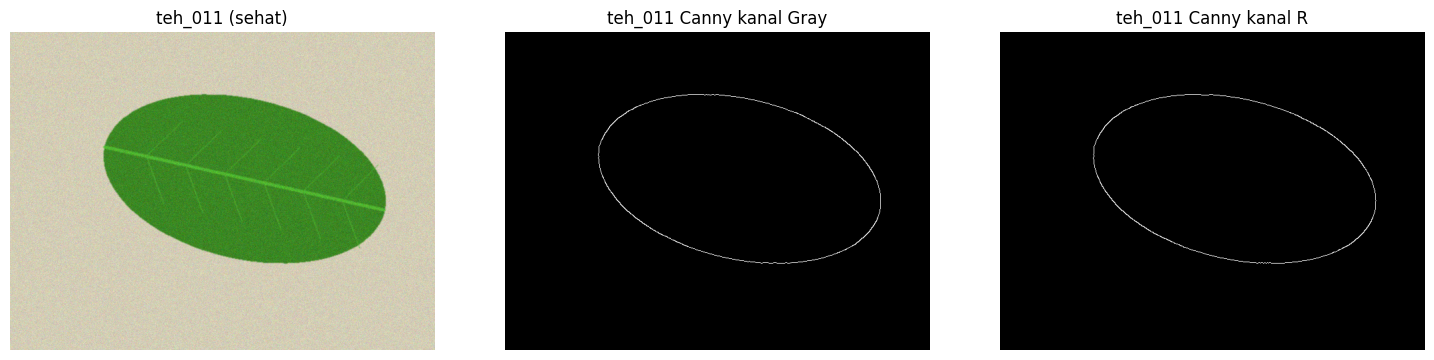

In [42]:
baris, panel, judul = [], [], []
for _, d in label[label.kelas == "sehat"].iterrows():
    img, md, mb = muat(d.nama_file)
    pra_ = praproses(img, PARAM)
    dalam = cv2.erode(md, np.ones((7, 7), np.uint8)) > 0  # bagian dalam daun

    for kanal, g in [("Gray", cv2.cvtColor(pra_, cv2.COLOR_BGR2GRAY)),
                     ("R", pra_[:, :, 2])]:
        e = tepi_canny(g)
        baris.append([d.kondisi_cahaya, kanal, int(((e > 0) & dalam).sum())])

        if d.nama_file == "teh_011.png":
            panel.append(e)
            judul.append(f"teh_011 Canny kanal {kanal}")

sehat = pd.DataFrame(
    baris,
    columns=["kondisi", "kanal", "piksel_tepi_di_dalam_daun"]
)

print(sehat.pivot_table(
    index="kondisi",
    columns="kanal",
    values="piksel_tepi_di_dalam_daun"
).round(1))

tampil(
    [muat("teh_011.png")[0]] + panel,
    ["teh_011 (sehat)"] + judul,
    ukuran=(15, 3.6)
)

**P2.1** Berdasarkan lembar hitung NMS dan Hysteresis:

1. Mengapa NMS membandingkan piksel dengan tetangga searah gradien, bukan searah tepi?
NMS bertujuan untuk menipiskan tepi dengan mencari nilai maksimum lokal. Gradien menunjuk ke arah perubahan intensitas paling tajam (tegak lurus terhadap garis tepi). Dengan membandingkan piksel di sepanjang arah gradien, kita memastikan bahwa kita mengambil titik paling tengah/tertinggi dari "bukit" gradien tersebut. Jika dibandingkan searah tepi, kita akan membandingkan piksel yang memiliki magnitudo serupa, sehingga garis tepi tidak akan menipis.

2. Mengapa hysteresis memakai dua ambang?
Untuk mengurangi derau (false positive) sekaligus menjaga kontinuitas tepi. Ambang atas (kuat) digunakan untuk menemukan titik awal tepi yang valid. Ambang bawah (lemah) digunakan untuk melacak sisa tepi yang terhubung dengan titik kuat, sehingga tepi tidak terputus-putus.

3. Mengapa piksel bernilai 90 pada soal (b) dibuang walaupun lebih besar dari ambang bawah?
Nilai 90 masuk dalam kategori tepi lemah (karena berada di antara ambang bawah 50 dan ambang atas 100). Berdasarkan aturan hysteresis, piksel lemah hanya dipertahankan jika terhubung (bertetangga) dengan piksel kuat. Pada baris tersebut, 90 bertetangga dengan 40 dan 30 (bukan tepi kuat), sehingga 90 dianggap derau dan dibuang (menjadi 0).

**P2.2** Berdasarkan Tabel 7 (Rata-rata hasil berdasarkan parameter):

1. Kombinasi mana yang memberi F1 tertinggi?
Berdasarkan gambar, kombinasi Sigma 2.0 dengan ambang 30/90 memberikan F1 tertinggi secara keseluruhan (F1 = 0.974).

2. Apakah kombinasi itu juga terbaik untuk bercak kelas ringan?
Tidak. Untuk kelas ringan (bercak kecil), Sigma 2.0 justru memiliki R_bercak paling rendah (0.830). Kombinasi terbaik untuk bercak ringan adalah Sigma 0.0 dengan ambang 30/90 yang memiliki R_bercak mencapai 0.990.

3. Jelaskan trade-off antara meredam derau dan mempertahankan bercak kecil:
Penghalusan (sigma tinggi) sangat efektif meredam derau (meningkatkan Presisi) dan membuat tepi daun besar lebih solid (F1 tinggi). Namun, proses blurring ini akan mengaburkan gradien pada bercak-bercak kecil hingga nilainya jatuh di bawah ambang, sehingga bercak kecil (ringan) hilang (Recall bercak menurun drastis).

**P2.3** Berdasarkan gambar hasil ambang otomatis (Median):

1. Hitung ambang otomatis dari median:
Berdasarkan gambar, median untuk kanal Gray pada kontras rendah adalah 159.9. Dengan rumus (1-s)*median dan (1+s)*median (s=0.33):

* Ambang bawah = (1 - 0.33) * 159.9 ≈ 107.1

* Ambang atas = (1 + 0.33) * 159.9 ≈ 212.6

2. Bandingkan dengan besarnya gradien: Pada citra kontras rendah kanal Gray, tepi daun memiliki magnitudo gradien yang sangat lemah (karena perbedaan warna daun dan latar sangat tipis). Ambang 107/212 terlalu tinggi untuk gradien yang lemah tersebut, sehingga hasil deteksinya nol (F1=0.000). Pada kanal R, kontras lebih baik sehingga gradien tepi lebih kuat dan lolos ambang.

3. Mengapa ambang dari intensitas tidak cocok untuk Canny?
Canny bekerja pada magnitudo gradien (perubahan nilai antar piksel), bukan nilai intensitas piksel itu sendiri. Median intensitas yang tinggi (misal 159) belum tentu memiliki gradien yang tinggi jika citranya seragam. Sebaliknya, citra gelap (intensitas rendah) bisa memiliki gradien tinggi jika ada tepi yang tajam. Oleh karena itu, ambang harus dihitung dari distribusi magnitudo gradien, bukan dari intensitas mentah.

**P2.4** Berdasarkan gambar hasil Canny Persentil:

1. Mengapa ambang dari persentil magnitudo lebih tahan terhadap perubahan kontras?
Karena persentil (misal P98) secara otomatis menyesuaikan diri dengan distribusi magnitudo gradien yang ada pada citra tersebut. Jika kontras turun, semua nilai gradien akan mengecil, dan nilai persentil juga akan ikut mengecil secara proporsional, sehingga tepi tetap terdeteksi.

2. Mengapa nilai q yang tepat berkaitan dengan proporsi piksel tepi?
Nilai q (misal 98) berarti kita hanya mengambil 2% piksel dengan gradien tertinggi sebagai tepi. Jika q terlalu rendah (misal P90, mengambil 10% piksel teratas), terlalu banyak piksel non-tepi (derau) yang ikut terambil, sehingga F1 jatuh (terlihat pada gambar P90 memiliki F1 sangat rendah, 0.081). Nilai q yang tepat harus mencerminkan persentase area tepi sebenarnya di dalam citra (biasanya sangat kecil, di bawah 5%).

P2.5 Berdasarkan gambar hasil Tepi pada daun sehat:

1. Mengapa tulang daun terdeteksi pada kanal Gray tetapi tidak pada kanal R?
Pada kanal Gray, tulang daun (yang berwarna lebih terang/kekuningan) memiliki perbedaan intensitas (kontras) yang cukup jelas dengan daging daun hijau di sekitarnya. Pada kanal R (Red), daging daun hijau memantulkan sedikit cahaya merah, sedangkan tulang daun juga memiliki nilai R yang mirip, sehingga kontrasnya sangat rendah (keduanya tampak gelap/seragam pada kanal R). Hal ini dibuktikan pada gambar, di mana kanal Gray mendeteksi 94 piksel tepi palsu di dalam daun, sedangkan kanal R mendeteksi 0.

2. Kanal R jauh lebih unggul dan direkomendasikan untuk digunakan dalam sistem SIMUTEH. Kanal R tidak hanya menonjolkan bercak cokelat (yang memiliki nilai R tinggi), tetapi juga secara alami menyembunyikan tulang daun, sehingga meminimalisir deteksi tepi palsu pada daun sehat.

P2.6 Keputusan Pemakaian Tepi pada SIMUTEH:
(Merujuk pada Tabel 8 di modul)

1. Menemukan batas daun: Ya, menggunakan gradien morfologi (dari mask) atau Canny pada kanal yang tepat. (Terbukti dari evaluasi P2.5).

2. Menemukan batas bercak: Ya, sangat direkomendasikan menggunakan Canny pada kanal R dengan parameter yang sesuai (karena F1 sangat tinggi, ~0.98).

3. Mengisi wilayah bercak (segmentasi): Tidak. Deteksi tepi hanya menghasilkan garis (kontur) 1 piksel. Untuk menghitung luas bercak, kita membutuhkan area yang terisi (mask biner utuh), yang harus dilakukan dengan operasi morfologi (seperti closing atau flood fill) pada Pertemuan 6.

4. Fitur bentuk bercak: Tidak, fitur bentuk seperti luas, kebulatan, dan rasio aspek dihitung dari komponen terhubung (connected components), bukan dari piksel tepi.

5. Mengapa tepi saja belum cukup untuk menghitung persentase luas bercak?
Persentase bercak dihitung dari perbandingan (Luas Area Bercak / Luas Area Daun). Tepi hanya memberi tahu di mana batas objek, bukan berapa banyak piksel di dalamnya. Selain itu, kebutuhan pengguna menuntut proses yang cepat; menghitung luas dari area yang sudah solid (mask) jauh lebih cepat dan efisien secara komputasi dibandingkan harus merekonstruksi area dari garis tepi yang mungkin masih terputus-putus.